# The Bias-Variance Tradeoff

Every ML interview and every debugging session circles back to one question: **is my model too simple or too complex?** The bias-variance tradeoff is the formal way to answer it — and it is the direct motivation for the next section in this roadmap, **Regularization**.

## 1. The Error Decomposition

For a fitted model $\hat{f}(x)$ predicting with the true function $f(x)$, the expected prediction error at a point $x$ decomposes into three parts:

$$
\text{Expected Error} = \underbrace{\text{Bias}^2[\hat{f}(x)]}_{\text{how wrong on average}} + \underbrace{\text{Var}[\hat{f}(x)]}_{\text{how much it wobbles}} + \underbrace{\sigma^2}_{\text{irreducible noise}}
$$

| Term | Meaning | Caused by |
|---|---|---|
| **Bias** | Error from wrong assumptions — the model systematically misses the true pattern | Model too simple, features too weak, not enough training |
| **Variance** | Error from sensitivity to the particular training set — refit on new data, get a very different model | Model too flexible, too many parameters, overfitting to noise |
| **Irreducible error** ($\sigma^2$) | Noise in the data itself that no model can remove | Measurement error, missing features, randomness |

**The tradeoff:** decreasing bias usually increases variance and vice versa. Model selection is about finding the sweet spot between the two — the minimum of the total error curve, not the minimum of training error.

## 2. Underfitting vs Overfitting

| Symptom | Underfitting (high bias) | Overfitting (high variance) |
|---|---|---|
| Training error | High | Very low |
| Validation/test error | High | Much higher than training |
| Gap between them | Small | Large |
| Analogy | A student who didn't study | A student who memorized the answer key |
| Typical fix | Bigger model, more features, train longer, reduce regularization | More data, simpler model, stronger regularization, early stopping, cross-validation |

A model is **just right** when both training and validation error are low and close together — you verify this with **learning curves**, not guesswork.

## 3. Seeing It: Polynomial Degree Demo

The classic experiment — fit polynomials of increasing degree to noisy data and watch bias fall while variance rises. Degree 1 is too rigid (underfits); degree 15 wraps itself around every noise point (overfits).

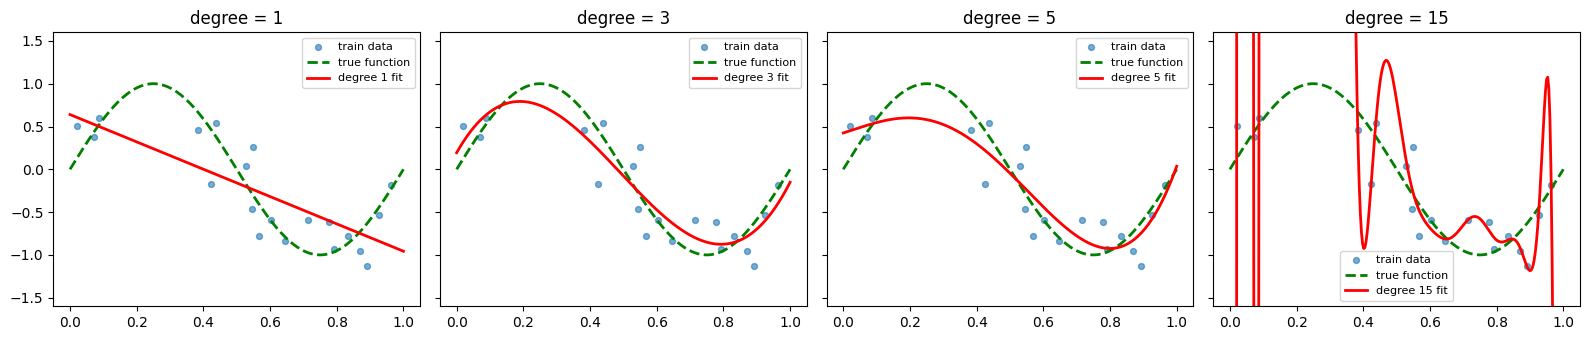

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

rng = np.random.RandomState(0)
n = 20
X = np.sort(rng.uniform(0, 1, n)).reshape(-1, 1)
true_f = lambda x: np.sin(2 * np.pi * x).ravel()
y_train = true_f(X) + rng.normal(0, 0.25, n)   # noisy training sample

# A fresh noisy sample to measure generalization
X_val = np.sort(rng.uniform(0, 1, 200)).reshape(-1, 1)
y_val = true_f(X_val) + rng.normal(0, 0.25, 200)

degrees = [1, 3, 5, 15]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)
for d, ax in zip(degrees, axes):
    pipe = Pipeline([("poly", PolynomialFeatures(d)),
                     ("lin", LinearRegression())])
    pipe.fit(X, y_train)
    xs = np.linspace(0, 1, 300).reshape(-1, 1)
    ax.scatter(X, y_train, s=18, alpha=0.6, label="train data")
    ax.plot(xs, true_f(xs), "g--", lw=2, label="true function")
    ax.plot(xs, pipe.predict(xs), "r-", lw=2, label=f"degree {d} fit")
    ax.set_ylim(-1.6, 1.6)
    ax.set_title(f"degree = {d}")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

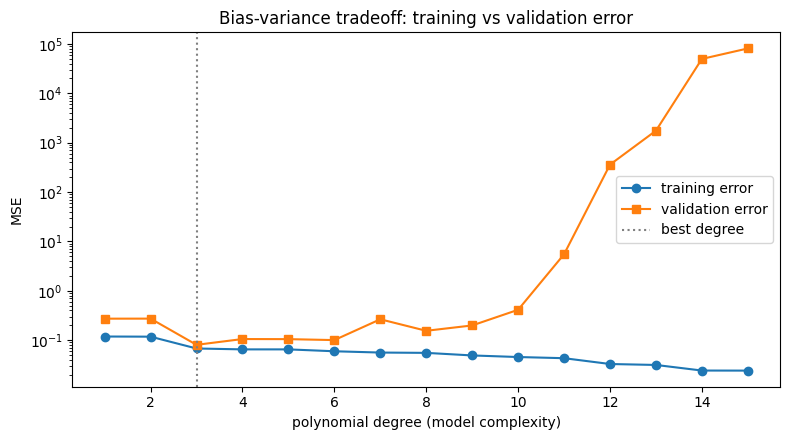

Best degree by validation error: 3
Degree  1 -> train 0.118 | val 0.272  (underfitting: both high)
Degree 3 -> train 0.068 | val 0.080  (sweet spot)
Degree 15 -> train 2.414e-02 | val 81175.218  (overfitting: train tiny, val explodes)


In [2]:
# Train vs validation error across degrees — the U-shaped total error
from sklearn.metrics import mean_squared_error

degrees = range(1, 16)
train_err, val_err = [], []
for d in degrees:
    pipe = Pipeline([("poly", PolynomialFeatures(d)),
                     ("lin", LinearRegression())])
    pipe.fit(X, y_train)
    train_err.append(mean_squared_error(y_train, pipe.predict(X)))
    val_err.append(mean_squared_error(y_val, pipe.predict(X_val)))

plt.figure(figsize=(8, 4.5))
plt.plot(degrees, train_err, "o-", label="training error")
plt.plot(degrees, val_err, "s-", label="validation error")
plt.axvline(int(np.argmin(val_err)) + 1, color="gray", ls=":", label="best degree")
plt.xlabel("polynomial degree (model complexity)")
plt.ylabel("MSE")
plt.yscale("log")
plt.title("Bias-variance tradeoff: training vs validation error")
plt.legend()
plt.tight_layout()
plt.show()

best = int(np.argmin(val_err)) + 1
print(f"Best degree by validation error: {best}")
print(f"Degree  1 -> train {train_err[0]:.3f} | val {val_err[0]:.3f}  (underfitting: both high)")
print(f"Degree {best} -> train {train_err[best-1]:.3f} | val {val_err[best-1]:.3f}  (sweet spot)")
print(f"Degree 15 -> train {train_err[14]:.3e} | val {val_err[14]:.3f}  (overfitting: train tiny, val explodes)")

## 4. Diagnosing with Learning Curves

Plot training and validation error against **training set size**:

- **Both curves converge high** → high bias (underfitting). More data will not help; you need a more expressive model or better features.
- **Large gap that narrows slowly** → high variance (overfitting). More data or regularization helps.

```python
from sklearn.model_selection import learning_curve

train_sizes, train_scores, val_scores = learning_curve(
    estimator, X, y, cv=5, scoring="neg_mean_squared_error",
    train_sizes=np.linspace(0.1, 1.0, 10))
# plot 1 - mean of scores vs train_sizes for both curves
```

## 5. Remedies Cheat Sheet

| Problem | High bias (underfit) | High variance (overfit) |
|---|---|---|
| Model | Use a more complex model (deeper tree, higher degree, bigger network) | Use a simpler model, prune the tree, reduce degree |
| Features | Add features, better feature engineering | Remove noisy features, feature selection |
| Data | Usually won't help | **Get more data** (the most reliable fix) |
| Training | Train longer | Early stopping |
| Regularization | Weaken it (higher `C` in SVM/logreg, smaller `alpha`) | Strengthen it (L1/L2 — see the next section) |
| Ensembling | Boosting attacks bias | Bagging attacks variance |

This table is why **Bagging/Random Forest** (Level 2, Section 6) reduce variance while **Gradient Boosting** can push down bias — the tradeoff explains the behavior of the ensembles you have already studied.

## 6. Key Takeaways

- Total error = **Bias² + Variance + irreducible noise** — you can only fight the first two.
- **Underfitting:** high train + high validation error. **Overfitting:** low train + much higher validation error.
- The tradeoff is managed, not eliminated: pick complexity via **cross-validation** (Level 3, Section 11), not by staring at training metrics.
- **Regularization** (next section) is the main dial for trading a little bias for a lot of variance reduction.
- Classic interview phrasing: *"Your model gets 99% on training and 62% on test — what is happening and what do you do?"* Now you have the full answer: high variance; get more data, regularize, simplify, or early-stop.